In [ ]:
pip install numpy matplotlib pillow

Image shape: (300, 300, 3)


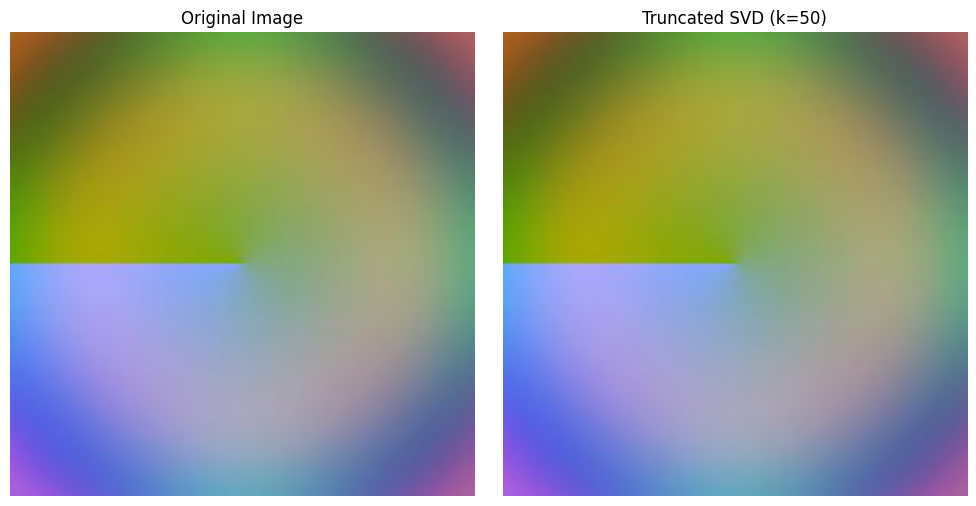

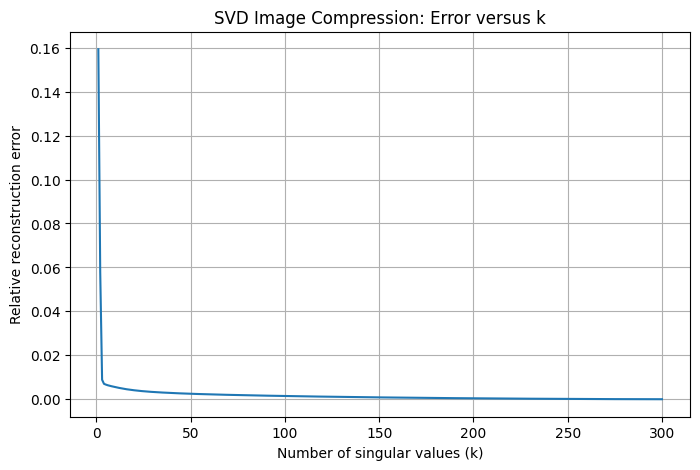

Relative error: 0.0024841450429101625


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request
import os

# 0. Download a sample image if image.jpg does not exist
if not os.path.exists("image.jpg"):
    print("Downloading sample image...")
    url = "https://upload.wikimedia.org/wikipedia/commons/e/e0/Placeholder_LCa.jpg"
    req = urllib.request.Request(
        url,
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    )
    try:
        with urllib.request.urlopen(req) as response, open("image.jpg", "wb") as out_file:
            out_file.write(response.read())
    except Exception as e:
        print(f"Could not download image: {e}. Generating a synthetic one instead.")
        # Generate a synthetic RGB image if download fails
        x, y = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-2, 2, 300))
        r = np.sin(x**2 + y**2)
        g = np.cos(x*y)
        b = np.arctan2(y, x)
        img_array = np.stack([r, g, b], axis=-1)
        img_array = ((img_array - img_array.min()) / (img_array.max() - img_array.min()) * 255).astype(np.uint8)
        Image.fromarray(img_array).save("image.jpg")

# 1. Load the image as an RGB array
image = Image.open("image.jpg").convert("RGB")
A = np.asarray(image, dtype=np.float64) / 255.0

height, width, channels = A.shape
print("Image shape:", A.shape)

# 2. Perform SVD separately on each color channel
U_list = []
S_list = []
Vt_list = []

for channel in range(channels):
    U, S, Vt = np.linalg.svd(
        A[:, :, channel],
        full_matrices=False
    )

    U_list.append(U)
    S_list.append(S)
    Vt_list.append(Vt)

# 3. Calculate relative reconstruction error for every k
max_k = min(height, width)
total_energy = sum(np.sum(S**2) for S in S_list)

errors = []

for k in range(1, max_k + 1):
    kept_energy = sum(
        np.sum(S[:k] ** 2) for S in S_list
    )

    error = np.sqrt(
        max(total_energy - kept_energy, 0) / total_energy
    )

    errors.append(error)

# 4. Reconstruct the image using a selected k
k = min(50, max_k)

reconstructed = np.zeros_like(A)

for channel in range(channels):
    U = U_list[channel]
    S = S_list[channel]
    Vt = Vt_list[channel]

    reconstructed[:, :, channel] = (
        U[:, :k] * S[:k]
    ) @ Vt[:k, :]

reconstructed = np.clip(reconstructed, 0, 1)

# 5. Display original and compressed images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(A)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed)
plt.title(f"Truncated SVD (k={k})")
plt.axis("off")

plt.tight_layout()
plt.show()

# 6. Plot reconstruction error versus k
plt.figure(figsize=(8, 5))
plt.plot(range(1, max_k + 1), errors)
plt.xlabel("Number of singular values (k)")
plt.ylabel("Relative reconstruction error")
plt.title("SVD Image Compression: Error versus k")
plt.grid(True)
plt.show()

print("Relative error:", errors[k - 1])

Image loaded successfully!
Image shape: (960, 640, 3)


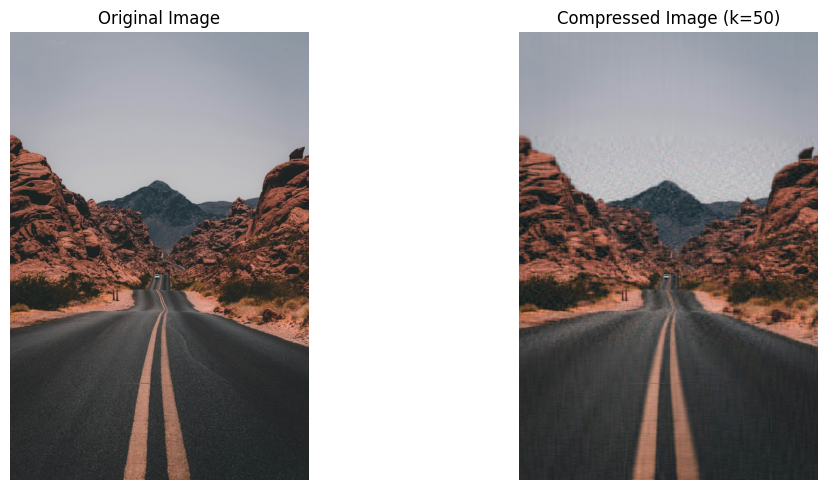

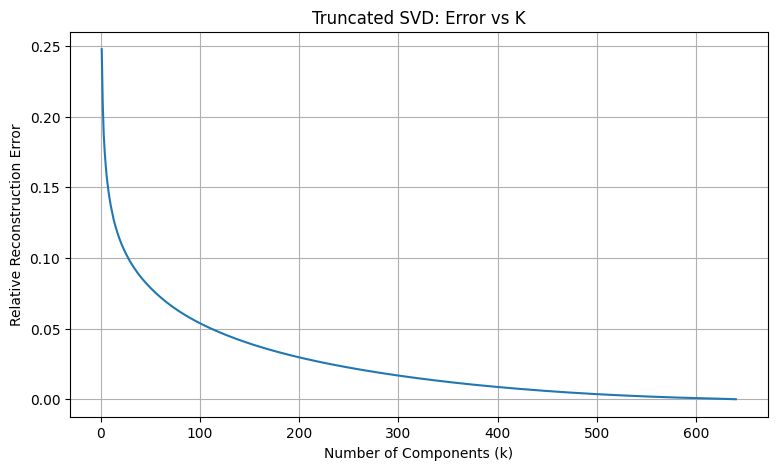

Selected K: 50
Relative Reconstruction Error: 0.07891484972774514


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO
from urllib.request import Request, urlopen

# ==========================================
# 1. LOAD IMAGE DIRECTLY FROM THE INTERNET
# ==========================================

IMAGE_URL = (
    "https://images.unsplash.com/"
    "photo-1500530855697-b586d89ba3ee"
    "?auto=format&fit=crop&w=640&q=80"
)

request = Request(
    IMAGE_URL,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urlopen(request, timeout=30) as response:
    content_type = response.headers.get_content_type()

    if not content_type.startswith("image/"):
        raise ValueError("The URL did not return an image.")

    image_bytes = response.read()

image = Image.open(BytesIO(image_bytes)).convert("RGB")

# Convert image into a NumPy array
A = np.asarray(image, dtype=np.float64) / 255.0

height, width, channels = A.shape

print("Image loaded successfully!")
print("Image shape:", A.shape)

# ==========================================
# 2. APPLY SVD TO EACH COLOR CHANNEL
# ==========================================

U_list = []
S_list = []
Vt_list = []

for channel in range(channels):

    U, S, Vt = np.linalg.svd(
        A[:, :, channel],
        full_matrices=False
    )

    U_list.append(U)
    S_list.append(S)
    Vt_list.append(Vt)

# ==========================================
# 3. CALCULATE ERROR FOR DIFFERENT K VALUES
# ==========================================

max_k = min(height, width)

total_energy = sum(
    np.sum(S**2) for S in S_list
)

cumulative_energy = [
    np.cumsum(S**2) for S in S_list
]

errors = []

for k in range(1, max_k + 1):

    kept_energy = sum(
        energy[k - 1]
        for energy in cumulative_energy
    )

    relative_error = np.sqrt(
        max(total_energy - kept_energy, 0)
        / total_energy
    )

    errors.append(relative_error)

# ==========================================
# 4. RECONSTRUCT IMAGE USING SELECTED K
# ==========================================

k = min(50, max_k)

reconstructed = np.zeros_like(A)

for channel in range(channels):

    U = U_list[channel]
    S = S_list[channel]
    Vt = Vt_list[channel]

    reconstructed[:, :, channel] = (
        U[:, :k] * S[:k]
    ) @ Vt[:k, :]

reconstructed = np.clip(reconstructed, 0, 1)

# ==========================================
# 5. DISPLAY ORIGINAL AND COMPRESSED IMAGES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(A)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed)
plt.title(f"Compressed Image (k={k})")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 6. PLOT ERROR VS K
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, max_k + 1),
    errors
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")

plt.title("Truncated SVD: Error vs K")

plt.grid(True)
plt.show()

# ==========================================
# 7. PRINT RESULTS
# ==========================================

print("Selected K:", k)

print(
    "Relative Reconstruction Error:",
    errors[k - 1]
)


Image loaded successfully!
Image shape: (960, 640, 3)


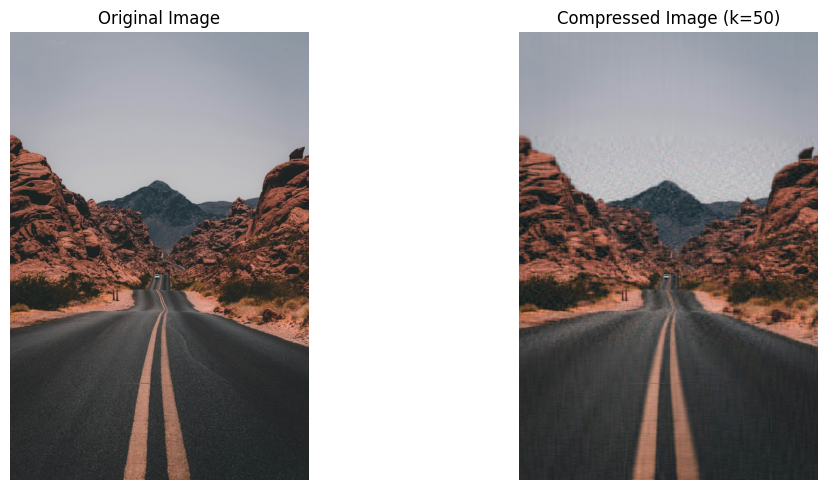

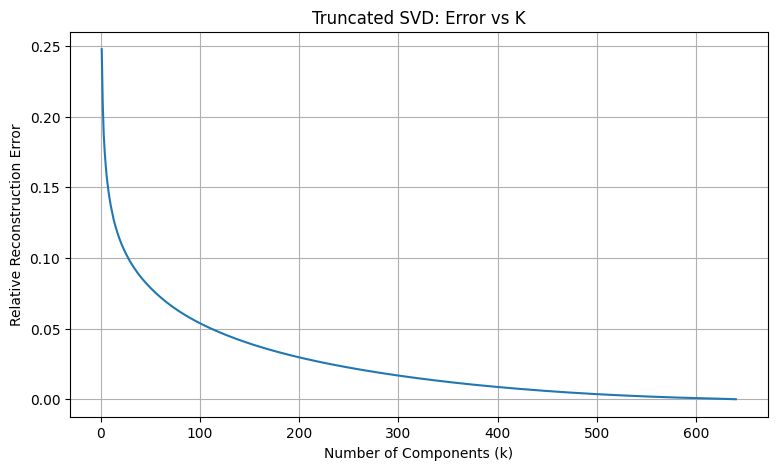

Selected K: 50
Relative Reconstruction Error: 0.07891484972774514


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO
from urllib.request import Request, urlopen

# ==========================================
# 1. LOAD IMAGE DIRECTLY FROM THE INTERNET
# ==========================================

IMAGE_URL = (
    "https://images.unsplash.com/"
    "photo-1500530855697-b586d89ba3ee"
    "?auto=format&fit=crop&w=640&q=80"
)

request = Request(
    IMAGE_URL,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urlopen(request, timeout=30) as response:
    content_type = response.headers.get_content_type()

    if not content_type.startswith("image/"):
        raise ValueError("The URL did not return an image.")

    image_bytes = response.read()

image = Image.open(BytesIO(image_bytes)).convert("RGB")

# Convert image into a NumPy array
A = np.asarray(image, dtype=np.float64) / 255.0

height, width, channels = A.shape

print("Image loaded successfully!")
print("Image shape:", A.shape)

# ==========================================
# 2. APPLY SVD TO EACH COLOR CHANNEL
# ==========================================

U_list = []
S_list = []
Vt_list = []

for channel in range(channels):

    U, S, Vt = np.linalg.svd(
        A[:, :, channel],
        full_matrices=False
    )

    U_list.append(U)
    S_list.append(S)
    Vt_list.append(Vt)

# ==========================================
# 3. CALCULATE ERROR FOR DIFFERENT K VALUES
# ==========================================

max_k = min(height, width)

total_energy = sum(
    np.sum(S**2) for S in S_list
)

cumulative_energy = [
    np.cumsum(S**2) for S in S_list
]

errors = []

for k in range(1, max_k + 1):

    kept_energy = sum(
        energy[k - 1]
        for energy in cumulative_energy
    )

    relative_error = np.sqrt(
        max(total_energy - kept_energy, 0)
        / total_energy
    )

    errors.append(relative_error)

# ==========================================
# 4. RECONSTRUCT IMAGE USING SELECTED K
# ==========================================

k = min(50, max_k)

reconstructed = np.zeros_like(A)

for channel in range(channels):

    U = U_list[channel]
    S = S_list[channel]
    Vt = Vt_list[channel]

    reconstructed[:, :, channel] = (
        U[:, :k] * S[:k]
    ) @ Vt[:k, :]

reconstructed = np.clip(reconstructed, 0, 1)

# ==========================================
# 5. DISPLAY ORIGINAL AND COMPRESSED IMAGES
# ==========================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(A)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed)
plt.title(f"Compressed Image (k={k})")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 6. PLOT ERROR VS K
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, max_k + 1),
    errors
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")

plt.title("Truncated SVD: Error vs K")

plt.grid(True)
plt.show()

# ==========================================
# 7. PRINT RESULTS
# ==========================================

print("Selected K:", k)

print(
    "Relative Reconstruction Error:",
    errors[k - 1]
)


Original data shape: (150, 4)
Reduced data shape: (150, 2)

Explained variance ratio:
PC1: 72.96%
PC2: 22.85%
PC3: 3.67%
PC4: 0.52%

Total variance preserved: 95.81%


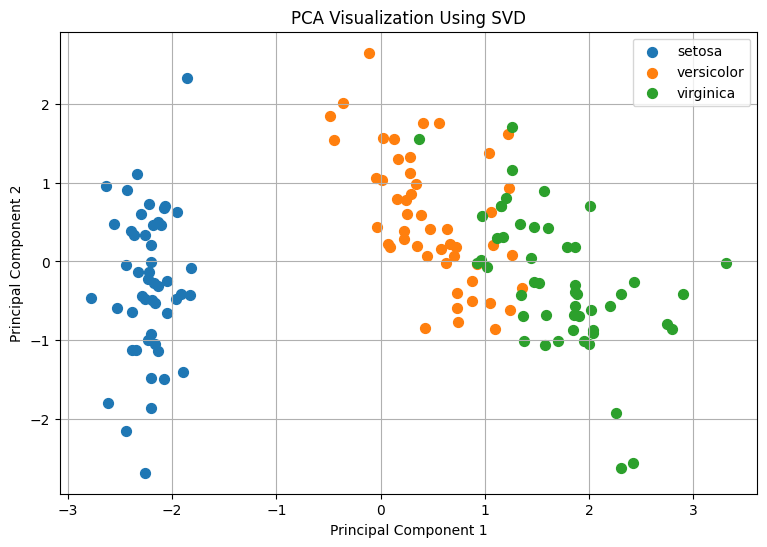

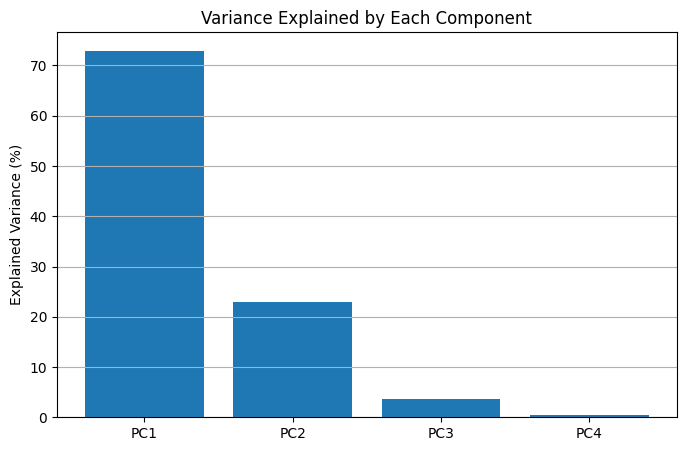

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# =====================================
# 1. LOAD DATASET
# =====================================

iris = load_iris()

X = iris.data
y = iris.target

print("Original data shape:", X.shape)

# 150 samples, 4 features

# =====================================
# 2. STANDARDIZE DATA
# =====================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# =====================================
# 3. APPLY SVD
# =====================================

U, S, Vt = np.linalg.svd(
    X_scaled,
    full_matrices=False
)

# =====================================
# 4. SELECT FIRST TWO COMPONENTS
# =====================================

components = Vt[:2, :]

# Project original data into 2 dimensions
X_pca = X_scaled @ components.T

print("Reduced data shape:", X_pca.shape)

# =====================================
# 5. CALCULATE EXPLAINED VARIANCE
# =====================================

explained_variance = S**2 / (len(X) - 1)

variance_ratio = (
    explained_variance /
    np.sum(explained_variance)
)

print("\nExplained variance ratio:")

for i, ratio in enumerate(variance_ratio):
    print(f"PC{i+1}: {ratio * 100:.2f}%")

print(
    "\nTotal variance preserved:",
    f"{np.sum(variance_ratio[:2]) * 100:.2f}%"
)

# =====================================
# 6. VISUALIZE PCA
# =====================================

plt.figure(figsize=(9, 6))

for class_id, name in enumerate(iris.target_names):

    plt.scatter(
        X_pca[y == class_id, 0],
        X_pca[y == class_id, 1],
        label=name,
        s=50
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization Using SVD")

plt.legend()
plt.grid(True)
plt.show()

# =====================================
# 7. VISUALIZE EXPLAINED VARIANCE
# =====================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["PC1", "PC2", "PC3", "PC4"],
    variance_ratio * 100
)

plt.ylabel("Explained Variance (%)")
plt.title("Variance Explained by Each Component")

plt.grid(axis="y")
plt.show()


Original dataset shape: (150, 4)
After PCA shape: (150, 2)


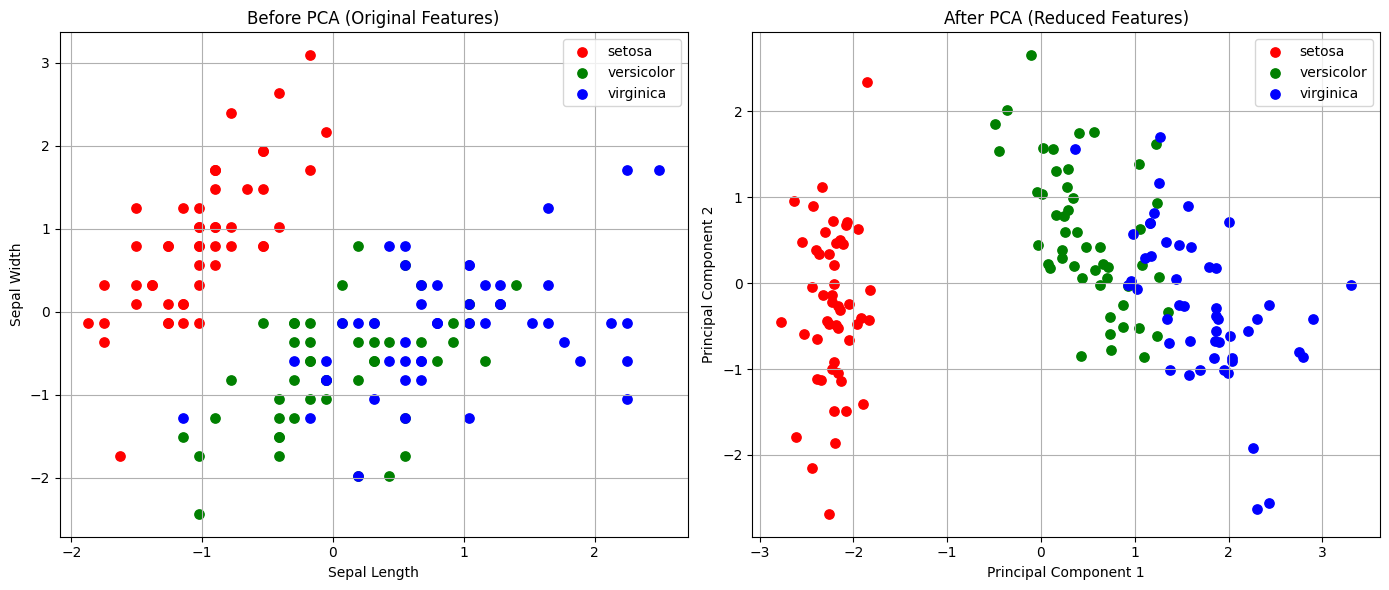


Explained Variance:
PC1: 72.96 %
PC2: 22.85 %
Total variance preserved: 95.81 %


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# =========================================
# 1. LOAD DATASET
# =========================================

iris = load_iris()

X = iris.data
y = iris.target

print("Original dataset shape:", X.shape)

# 150 samples, 4 features

# =========================================
# 2. STANDARDIZE DATA
# =========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# =========================================
# 3. BEFORE PCA
# =========================================

# Visualize the first two original features
X_before = X_scaled[:, :2]

# =========================================
# 4. APPLY PCA USING SVD
# =========================================

U, S, Vt = np.linalg.svd(
    X_scaled,
    full_matrices=False
)

# Select first two principal components
components = Vt[:2, :]

# Project data into two dimensions
X_after = X_scaled @ components.T

print("After PCA shape:", X_after.shape)

# =========================================
# 5. VISUALIZE BEFORE AND AFTER PCA
# =========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors = ["red", "green", "blue"]

for class_id, name in enumerate(iris.target_names):

    mask = y == class_id

    # BEFORE PCA
    axes[0].scatter(
        X_before[mask, 0],
        X_before[mask, 1],
        label=name,
        color=colors[class_id],
        s=45
    )

    # AFTER PCA
    axes[1].scatter(
        X_after[mask, 0],
        X_after[mask, 1],
        label=name,
        color=colors[class_id],
        s=45
    )

# Before PCA labels
axes[0].set_title("Before PCA (Original Features)")
axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")
axes[0].legend()
axes[0].grid(True)

# After PCA labels
axes[1].set_title("After PCA (Reduced Features)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# =========================================
# 6. EXPLAINED VARIANCE
# =========================================

variance = S**2 / (len(X) - 1)

variance_ratio = variance / np.sum(variance)

print("\nExplained Variance:")

print(
    "PC1:",
    round(variance_ratio[0] * 100, 2), "%"
)

print(
    "PC2:",
    round(variance_ratio[1] * 100, 2), "%"
)

print(
    "Total variance preserved:",
    round(np.sum(variance_ratio[:2]) * 100, 2), "%"
)
